# 2.11 · Choosing a prior: families, shapes and prior-predictive checks

**Before this:** [2.03](2-03_probability_distributions.ipynb) (distributions), [2.08](2-08_bayesian_linear_map.ipynb) (prior × likelihood), [2.09](2-09_regularisation_smoothing.ipynb) (smoothing priors).
**You will be able to:** match a prior family to what you actually know (sign, scale, tails, a fixed total,
smoothness); see why a "flat" prior is flat only in one parameterisation; check a prior before fitting by simulating
data from it, and revise it; tell, patch by patch, whether an answer comes from the data or from the prior.
**Optional sections:** 7 (improper priors).

A prior is part of the model, like the forward model and the noise model. It is where everything known before the
data enters: that slip on a right-lateral fault is positive, that a viscosity spans orders of magnitude, that a
seismic moment fixes the total, that slip varies smoothly. 2.09 showed priors acting as regularisers; this notebook
shows the menu of prior families, what each one assumes, and the habit that makes priors defensible: simulate from
the prior before looking at the fit.

**Words this notebook defines:** prior family, Gaussian (normal), Laplace, Student-t, uniform, half-normal,
truncated normal, log-normal, Dirichlet, concentration parameter, parameterisation, Jacobian, prior-predictive
distribution, prior-predictive check, shrinkage, improper prior.

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| one number (sections 1, 3) | 1 (a slip value or a viscosity) | none: prior only | none | n/a |
| slip profile, prior draws (sections 2, 4) | 30 slip patches, 1 km each, 0-30 km | none: prior only | none | n/a |
| antiplane fault (sections 5-7, as in 2.07) | 30 slip patches | 24 stations, σ = 3 mm | screw-dislocation Green's functions, $\mathbf d = \mathbf G\mathbf s$ | linear |

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st
import bayeskit as bk
from bayeskit import diagnostics as D, style as S
import numpyro
numpyro.set_host_device_count(4)                 # 4 NUTS chains in parallel (before any JAX computation)
import jax, jax.numpy as jnp
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

T0 = time.time()
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(2)

## 1. One number, many priors

**In plain words.** A prior family is a shape for "what values are plausible before the data". The families below
differ in three things that matter in practice: whether negative values are allowed, how fast very large values
become implausible (the **tails**), and whether the plausible range is set in absolute terms ("about 1 m, give or take
1 m") or in ratios ("somewhere between 0.1 and 10 m").

**Precisely.** For one number $x$ (the **support** of a distribution is the set of values it allows; "up to a
constant" means the normalising factor that makes the total probability 1 is left out):

| family | density (up to a constant) | support | use it when you know |
|---|---|---|---|
| **Gaussian** = **normal** $\mathcal N(\mu,\sigma^2)$ | $e^{-(x-\mu)^2/2\sigma^2}$ | all $x$ | a typical value and a typical deviation; large deviations very unlikely |
| **Laplace** | $e^{-\lvert x-\mu\rvert/b}$ | all $x$ | most values small, a few large (its MAP gives L1/sparsity, 2.09) |
| **Student-t** ($\nu$ degrees of freedom) | $(1 + (x-\mu)^2/\nu s^2)^{-(\nu+1)/2}$ | all $x$ | a typical scale, but occasional much larger values (heavy tails; robust) |
| **uniform** $\mathcal U(a,b)$ | 1 inside $[a,b]$ | $[a,b]$ | hard bounds and nothing else |
| **half-normal** | $e^{-x^2/2\sigma^2}$ | $x\ge 0$ | the sign, and a scale |
| **truncated normal** | $e^{-(x-\mu)^2/2\sigma^2}$ | $x\ge 0$ (or any bounds) | a sign, a typical value and a deviation |
| **log-normal** | $\frac1x e^{-(\ln x-\mu)^2/2s^2}$ | $x>0$ | an order of magnitude: $\ln x$ is Gaussian |

"Gaussian" and "normal" are two names for the same distribution (after Gauss; "normal" became common later). There is
no difference between them. The Student-t's **degrees of freedom** $\nu$ set how heavy its tails are (heavy tails,
2.03: large values far more likely than a Gaussian allows): small $\nu$ gives very heavy tails, and as $\nu$ grows it
approaches the Gaussian. The log-normal's **log-sd** is the standard deviation of $\ln x$: a log-sd of 1 means a
typical spread of a factor $e\approx 2.7$ either side of the median.

**Worked example.** Symmetric families scaled to the same standard deviation (1), and positive families scaled to
the same median (1), so that only the shape differs. The code prints the tail probabilities.

In [2]:
x = np.linspace(-6, 6, 2401)
sym = {"Gaussian (normal)": st.norm(0, 1), "Laplace": st.laplace(0, 1 / np.sqrt(2)),
       "Student-t, ν = 3": st.t(3, 0, 1 / np.sqrt(3)), "uniform": st.uniform(-np.sqrt(3), 2 * np.sqrt(3))}
xp = np.linspace(1e-4, 6, 2401)
hn_scale = 1 / st.halfnorm.median()
pos = {"half-normal": st.halfnorm(0, hn_scale), "truncated normal N(1, 1), x > 0": st.truncnorm(-1, np.inf, 1, 1),
       "log-normal (median 1, log-sd 1)": st.lognorm(1.0, 0, 1.0)}
print("symmetric families, all with standard deviation 1:")
for k, dd in sym.items():
    print(f"  {k:24s} sd {dd.std():.3f}   P(|x| > 2) = {2 * dd.sf(2):.4f}   P(|x| > 3) = {2 * dd.sf(3):.5f}   P(|x| > 5) = {2 * dd.sf(5):.2e}")
print("positive families:")
for k, dd in pos.items():
    print(f"  {k:34s} median {dd.median():.3f}   P(x < 0.1) = {dd.cdf(0.1):.4f}   P(x > 3) = {dd.sf(3):.4f}   P(x > 10) = {dd.sf(10):.2e}")

symmetric families, all with standard deviation 1:
  Gaussian (normal)        sd 1.000   P(|x| > 2) = 0.0455   P(|x| > 3) = 0.00270   P(|x| > 5) = 5.73e-07
  Laplace                  sd 1.000   P(|x| > 2) = 0.0591   P(|x| > 3) = 0.01437   P(|x| > 5) = 8.49e-04
  Student-t, ν = 3         sd 1.000   P(|x| > 2) = 0.0405   P(|x| > 3) = 0.01385   P(|x| > 5) = 3.24e-03
  uniform                  sd 1.000   P(|x| > 2) = 0.0000   P(|x| > 3) = 0.00000   P(|x| > 5) = 0.00e+00
positive families:
  half-normal                        median 1.000   P(x < 0.1) = 0.0538   P(x > 3) = 0.0430   P(x > 10) = 1.53e-11
  truncated normal N(1, 1), x > 0    median 1.200   P(x < 0.1) = 0.0302   P(x > 3) = 0.0270   P(x > 10) = 1.34e-19
  log-normal (median 1, log-sd 1)    median 1.000   P(x < 0.1) = 0.0107   P(x > 3) = 0.1360   P(x > 10) = 1.07e-02


saved figures/2-11_families_1d.png


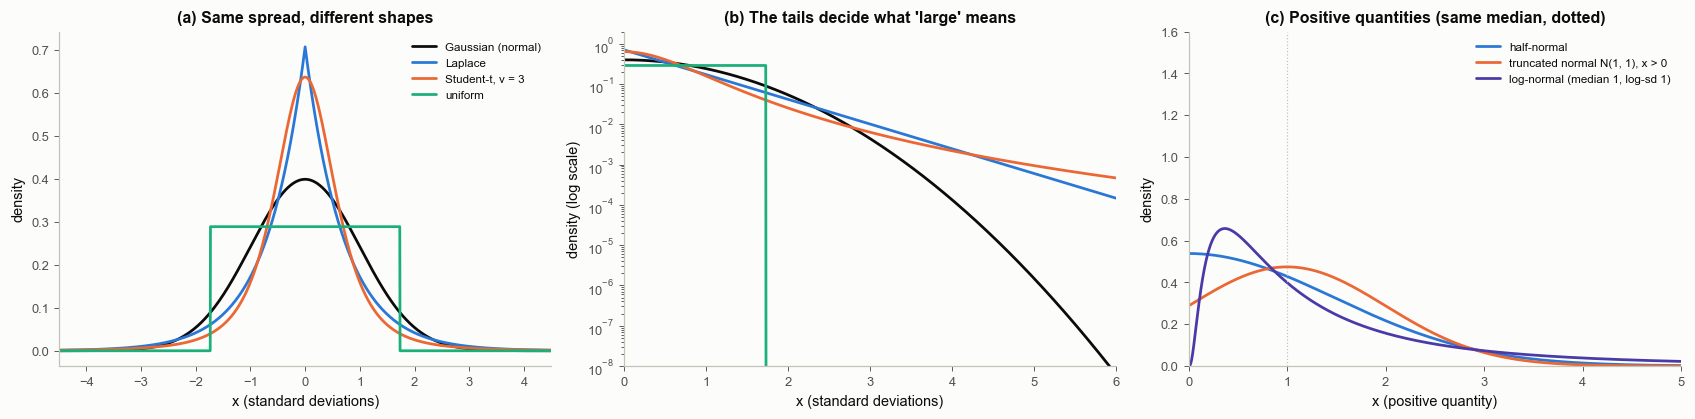

In [3]:
cols = [S.INK, S.BLUE, S.ORANGE, S.AQUA]
fig, axs = plt.subplots(1, 3, figsize=(15.5, 3.9))
for (k, dd), c in zip(sym.items(), cols):
    axs[0].plot(x, dd.pdf(x), color=c, lw=1.8, label=k)
    axs[1].semilogy(x, np.maximum(dd.pdf(x), 1e-12), color=c, lw=1.8, label=k)
axs[0].set_xlim(-4.5, 4.5); axs[0].set_xlabel("x (standard deviations)"); axs[0].set_ylabel("density")
axs[0].set_title("(a) Same spread, different shapes"); axs[0].legend(fontsize=7.6, loc="upper right")
axs[1].set_ylim(1e-8, 2); axs[1].set_xlim(0, 6); axs[1].set_xlabel("x (standard deviations)"); axs[1].set_ylabel("density (log scale)")
axs[1].set_title("(b) The tails decide what 'large' means")
for (k, dd), c in zip(pos.items(), [S.BLUE, S.ORANGE, S.VIOLET]):
    axs[2].plot(xp, dd.pdf(xp), color=c, lw=1.8, label=k)
axs[2].axvline(1, color=S.AXIS, lw=0.8, ls=":")
axs[2].set_xlim(0, 5); axs[2].set_ylim(0, 1.6)
axs[2].set_xlabel("x (positive quantity)"); axs[2].set_ylabel("density")
axs[2].set_title("(c) Positive quantities (same median, dotted)"); axs[2].legend(fontsize=7.6, loc="upper right")
fig.tight_layout()
bk.savefig(fig, "2-11_families_1d")
plt.show()

**How to read it.** (a) With the same standard deviation the four symmetric shapes look similar near zero. (b) On a
log scale they are not: the Gaussian tail falls fastest, Laplace falls as a straight line, the Student-t tail stays
high, and the uniform has no tail at all (printed: the probability of a value beyond 5 standard deviations differs
by many orders of magnitude). A Gaussian prior says a 5-sd value is essentially impossible; a Student-t says it is
merely unusual. (c) Positive families with the same median: the half-normal is largest at zero, the truncated normal
has a preferred value, the log-normal is skewed with a long right tail.

**Common misreadings.**
* *"Gaussian and normal priors are different choices."* Same distribution, two names.
* *"If two priors have the same mean and standard deviation, they say the same thing."* They agree on typical values
  and disagree, sometimes by orders of magnitude, on large ones (b), and large values are what outliers and sharp
  slip features are made of.

## 2. The same families on a slip profile

**In plain words.** Put one prior on each of 30 patches, independently, and draw whole slip profiles. The pictures
show what each family "believes" a fault looks like before any data. A smooth prior (correlated patches, 2.09, 2.12)
is added for comparison.

**Precisely.** Independent priors on each patch: $p(\mathbf s) = \prod_j p(s_j)$. The smooth prior is a Gaussian
with covariance $C_{ij} = \sigma^2\exp(-\tfrac12(z_i-z_j)^2/\ell^2)$ (squared exponential, $\ell$ = 5 km; 2.12
explains the family). All have a typical slip of order 1 m.

In [4]:
Nf = 30
z_edges = np.linspace(0.0, 30.0, Nf + 1)
zc = 0.5 * (z_edges[1:] + z_edges[:-1])
wz = np.diff(z_edges)                                                       # patch widths (km)


def sq_exp_cov(ell, sd):
    dz = zc[:, None] - zc[None, :]
    return sd ** 2 * np.exp(-0.5 * (dz / ell) ** 2) + 1e-9 * np.eye(Nf)


ndraw = 4
r2 = np.random.default_rng(5)
draws2 = {
    "Gaussian, sd 1 m": r2.normal(0, 1, (ndraw, Nf)),
    "Laplace, sd 1 m": r2.laplace(0, 1 / np.sqrt(2), (ndraw, Nf)),
    "Student-t ν = 3, scale 0.58 m": st.t(3, 0, 1 / np.sqrt(3)).rvs((ndraw, Nf), random_state=r2),
    "half-normal, scale 1 m": np.abs(r2.normal(0, 1, (ndraw, Nf))),
    "log-normal, median 1 m": np.exp(r2.normal(0, 1, (ndraw, Nf))),
    "smooth Gaussian, sd 1 m, ℓ = 5 km": r2.multivariate_normal(np.zeros(Nf), sq_exp_cov(5.0, 1.0), ndraw),
}
big = {k: r2.normal(0, 1, (20000, Nf)) for k in ["Gaussian"]}
lap = r2.laplace(0, 1 / np.sqrt(2), (20000, Nf))
print("share of patch values within 0.05 sd of zero: Gaussian %.3f, Laplace %.3f (a sparse vector would have most of them there)"
      % (np.mean(np.abs(big["Gaussian"]) < 0.05), np.mean(np.abs(lap) < 0.05)))
t3 = st.t(3, 0, 1 / np.sqrt(3)).rvs((20000, Nf), random_state=r2)
print("largest |slip| in a 30-patch draw, median over 20,000 draws: Gaussian %.2f m, Laplace %.2f m, Student-t %.2f m"
      % (np.median(np.abs(big["Gaussian"]).max(1)), np.median(np.abs(lap).max(1)), np.median(np.abs(t3).max(1))))


def step(ax, m, **kw):
    ax.plot(np.repeat(m, 2), np.c_[z_edges[:-1], z_edges[1:]].ravel(), **kw)

share of patch values within 0.05 sd of zero: Gaussian 0.040, Laplace 0.068 (a sparse vector would have most of them there)
largest |slip| in a 30-patch draw, median over 20,000 draws: Gaussian 2.28 m, Laplace 2.67 m, Student-t 2.51 m


saved figures/2-11_families_profiles.png


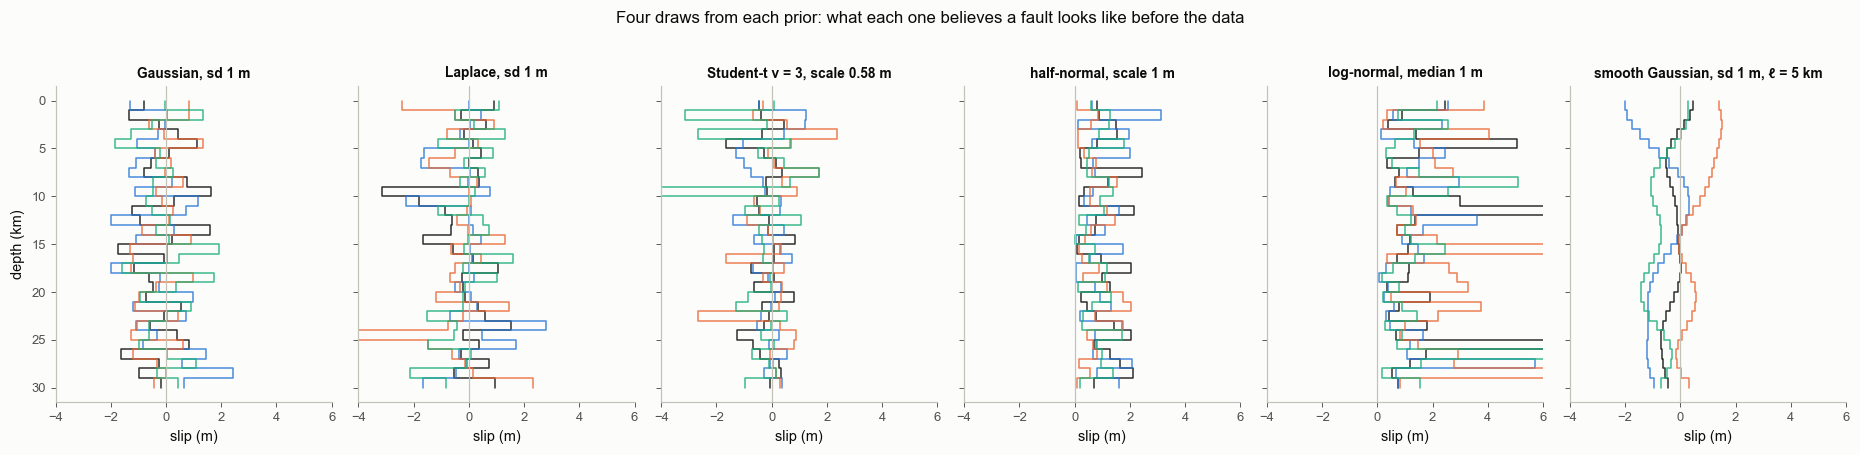

In [5]:
fig, axs = plt.subplots(1, 6, figsize=(17, 4.0), sharey=True)
shades = [S.INK, S.BLUE, S.ORANGE, S.AQUA]
for ax, (k, X) in zip(axs, draws2.items()):
    for i in range(ndraw):
        step(ax, X[i], color=shades[i], lw=1.0, alpha=0.85)
    ax.axvline(0, color=S.AXIS, lw=0.8)
    ax.set_title(k, fontsize=9)
    ax.set_xlabel("slip (m)")
axs[0].invert_yaxis(); axs[0].set_ylabel("depth (km)")
for ax in axs:
    ax.set_xlim(-4, 6)
fig.suptitle("Four draws from each prior: what each one believes a fault looks like before the data", fontsize=11, y=1.02)
fig.tight_layout()
bk.savefig(fig, "2-11_families_profiles")
plt.show()

**How to read it.** Independent priors give jagged profiles, because nothing ties one patch to the next. The Laplace
draws are not sparse: the share of values near zero is only somewhat larger than for the Gaussian (printed); the
sparse solutions of 2.09 come from the MAP, not from the prior's draws. The Student-t has occasional big spikes
(printed largest values). Half-normal and log-normal are positive everywhere; the log-normal has rare large patches.
Only the smooth Gaussian looks like the slip models in papers, and that is a modelling decision, not a fact about
faults.

**Common misreadings.**
* *"A Laplace prior believes slip is sparse."* Its draws are not sparse (printed). Its MAP is.
* *"Independent priors are the neutral choice."* They are a strong statement: neighbouring patches have nothing to
  do with each other.

## 3. Flat is not neutral: priors depend on the parameterisation

**In plain words.** "I know nothing, so I use a uniform prior" sounds neutral, but uniform in *what*? A viscosity
between $10^{18}$ and $10^{21}$ Pa s that is uniform in the viscosity itself puts almost all its probability in the
top decade. Uniform in the logarithm puts equal probability in each decade. They are different beliefs, and with weak
data they give different answers.

**Precisely.** If $x$ has density $p_x(x)$ and $y = g(x)$ is a one-to-one transformation, then
$p_y(y) = p_x(g^{-1}(y))\,\lvert dg^{-1}/dy\rvert$. The factor $\lvert dg^{-1}/dy\rvert$ is the **Jacobian**. For
$u = \log_{10}\eta$ and $\eta$ uniform on $[a,b]$: $p_u(u) = \ln(10)\,10^{u}/(b-a)$, which rises steeply with $u$.
The same rule is why a MAP changes when you change variables (2.08): densities, and hence their peaks, move.

**Worked example.** 200,000 draws of a viscosity, uniform in η and uniform in log η, both on $[10^{18}, 10^{21}]$ Pa s.

In [6]:
a_eta, b_eta = 1e18, 1e21
n3 = 200_000
eta_lin = np.random.default_rng(3).uniform(a_eta, b_eta, n3)
eta_log = 10 ** np.random.default_rng(4).uniform(18, 21, n3)
for nm, e_ in [("uniform in eta", eta_lin), ("uniform in log10 eta", eta_log)]:
    shares = [np.mean((e_ >= 10 ** k) & (e_ < 10 ** (k + 1))) for k in (18, 19, 20)]
    print(f"{nm:22s}: share per decade 1e18-1e19 {shares[0]:.4f}, 1e19-1e20 {shares[1]:.4f}, 1e20-1e21 {shares[2]:.4f};"
          f"  median {np.median(e_):.2e} Pa s")
print("exact share of the top decade under uniform-in-eta: (1e21 - 1e20) / (1e21 - 1e18) = %.4f" % ((1e21 - 1e20) / (1e21 - 1e18)))

uniform in eta        : share per decade 1e18-1e19 0.0089, 1e19-1e20 0.0908, 1e20-1e21 0.9003;  median 5.02e+20 Pa s
uniform in log10 eta  : share per decade 1e18-1e19 0.3324, 1e19-1e20 0.3331, 1e20-1e21 0.3345;  median 3.19e+19 Pa s
exact share of the top decade under uniform-in-eta: (1e21 - 1e20) / (1e21 - 1e18) = 0.9009


saved figures/2-11_flat_not_neutral.png


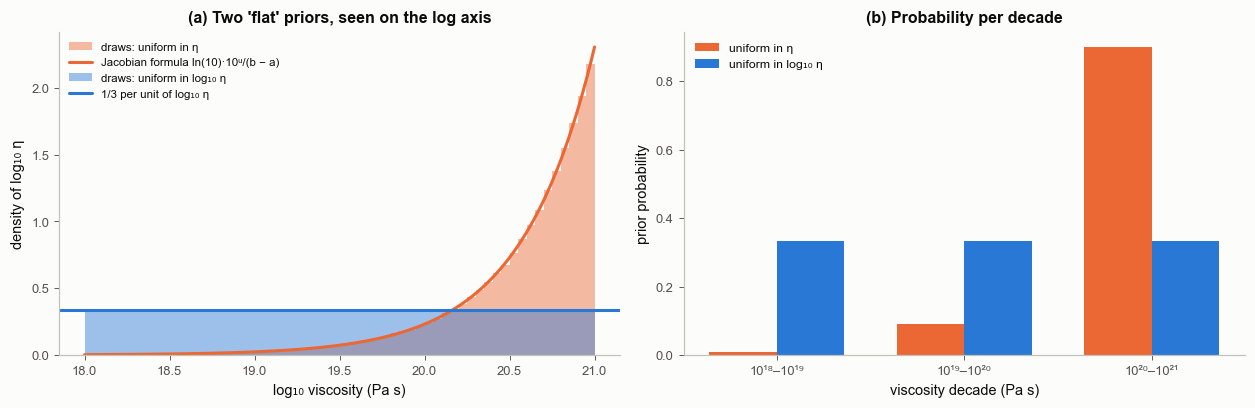

In [7]:
u = np.linspace(18, 21, 400)
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axs[0]
bins = np.linspace(18, 21, 61)
ax.hist(np.log10(eta_lin), bins=bins, density=True, color=S.ORANGE, alpha=0.45, label="draws: uniform in η")
ax.plot(u, np.log(10) * 10 ** u / (b_eta - a_eta), color=S.ORANGE, lw=2, label="Jacobian formula ln(10)·10ᵘ/(b − a)")
ax.hist(np.log10(eta_log), bins=bins, density=True, color=S.BLUE, alpha=0.45, label="draws: uniform in log₁₀ η")
ax.axhline(1 / 3, color=S.BLUE, lw=2, label="1/3 per unit of log₁₀ η")
ax.set_xlabel("log₁₀ viscosity (Pa s)"); ax.set_ylabel("density of log₁₀ η")
ax.set_title("(a) Two 'flat' priors, seen on the log axis")
ax.legend(fontsize=7.5, loc="upper left")
ax = axs[1]
dec = np.arange(3)
w_ = 0.36
lin_sh = [np.mean((eta_lin >= 10.0 ** (18 + k)) & (eta_lin < 10.0 ** (19 + k))) for k in dec]   # 10.0: integer 10**19 overflows
log_sh = [np.mean((eta_log >= 10.0 ** (18 + k)) & (eta_log < 10.0 ** (19 + k))) for k in dec]
ax.bar(dec - w_ / 2, lin_sh, w_, color=S.ORANGE, label="uniform in η")
ax.bar(dec + w_ / 2, log_sh, w_, color=S.BLUE, label="uniform in log₁₀ η")
ax.set_xticks(dec); ax.set_xticklabels(["10¹⁸–10¹⁹", "10¹⁹–10²⁰", "10²⁰–10²¹"])
ax.set_xlabel("viscosity decade (Pa s)"); ax.set_ylabel("prior probability")
ax.set_title("(b) Probability per decade")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-11_flat_not_neutral")
plt.show()

**How to read it.** (a) On a log axis the uniform-in-η prior is not flat at all: its density rises tenfold per
decade, and the histogram of draws follows the Jacobian formula. The uniform-in-log prior is flat on this axis.
(b) The uniform-in-η prior puts most of its probability (printed) in the top decade, so it is a strong belief in
high viscosity, not ignorance. For a quantity known only to an order of magnitude, a log-uniform or log-normal prior
says what you mean.

**Common misreadings.**
* *"A uniform prior is uninformative."* It is uniform in one parameterisation and strongly informative in others.
* *"The prior only matters if the data are weak."* True, and weakly constrained parameters (deep slip, viscosity,
  friction) are exactly where the choice shows (section 6).

## 4. The Dirichlet prior: sharing a fixed total

**In plain words.** Sometimes you know a total better than its parts. The **seismic moment**
$M_0 = \mu\times\text{area}\times\text{average slip}$ ($\mu$ the shear modulus, the rock's stiffness), measured
from seismic waves, is an example: it fixes the total slip times area (the **potency**; on this 2-D fault, the sum
of slip × patch width, in m·km) much better than a geodetic network constrains each patch. A **Dirichlet** prior describes how a total of 1 is shared among $K$ parts: every share is
non-negative and the shares add to one. Multiply by the total and you have a positive slip profile with a known sum.

**Precisely.** $\mathbf w\sim\text{Dirichlet}(\alpha_1,\dots,\alpha_K)$ has density
$\propto\prod_k w_k^{\alpha_k - 1}$ on the simplex $\{w_k\ge 0,\ \sum_k w_k = 1\}$. With all $\alpha_k = \alpha$:
the mean share is $1/K$, and the **concentration parameter** $\alpha$ sets the spread,
$\mathrm{Var}(w_k) = \frac{(K-1)}{K^2(K\alpha + 1)}$. $\alpha = 1$ is uniform over the simplex; $\alpha < 1$ prefers
a few large shares (concentrated slip); $\alpha > 1$ prefers even sharing. A Dirichlet draw is $K$ independent
Gamma($\alpha$, 1) numbers divided by their sum, which is how the code below draws it (the **Gamma** distribution
is a family of positive numbers; with shape $\alpha$ small, most draws are near zero and a few are large). The set of
all possible share vectors, $\{w_k\ge 0,\ \sum_k w_k = 1\}$, is called the **simplex**; for $K = 3$ it is a
triangle.

**Worked example.** Three parts (drawn in a triangle) and 30 patches sharing a potency of 20 m·km, for three values
of $\alpha$; the variance formula is checked against the draws.

In [8]:
def dirichlet_draws(alpha, K, n, seed):
    g = np.random.default_rng(seed).gamma(alpha, 1.0, (n, K))
    return g / g.sum(1, keepdims=True)


alphas = [0.3, 1.0, 5.0]
P0 = 20.0                                                                   # potency (m km), the total to be shared
for a_ in alphas:
    W = dirichlet_draws(a_, Nf, 50_000, 10)
    print(f"alpha = {a_:3.1f}, K = {Nf}: mean share {W.mean():.4f} (1/K = {1 / Nf:.4f}); var of a share {W[:, 0].var():.2e} "
          f"(formula {(Nf - 1) / (Nf ** 2 * (Nf * a_ + 1)):.2e}); largest share in a draw, median {np.median(W.max(1)):.3f}; "
          f"sum of shares {W.sum(1).min():.6f} to {W.sum(1).max():.6f}")


def tern(W):                                                                # barycentric -> 2-D triangle coordinates
    return W[:, 1] + 0.5 * W[:, 2], np.sqrt(3) / 2 * W[:, 2]

alpha = 0.3, K = 30: mean share 0.0333 (1/K = 0.0333); var of a share 3.19e-03 (formula 3.22e-03); largest share in a draw, median 0.227; sum of shares 1.000000 to 1.000000
alpha = 1.0, K = 30: mean share 0.0333 (1/K = 0.0333); var of a share 1.03e-03 (formula 1.04e-03); largest share in a draw, median 0.127; sum of shares 1.000000 to 1.000000
alpha = 5.0, K = 30: mean share 0.0333 (1/K = 0.0333); var of a share 2.16e-04 (formula 2.13e-04); largest share in a draw, median 0.069; sum of shares 1.000000 to 1.000000


saved figures/2-11_dirichlet.png


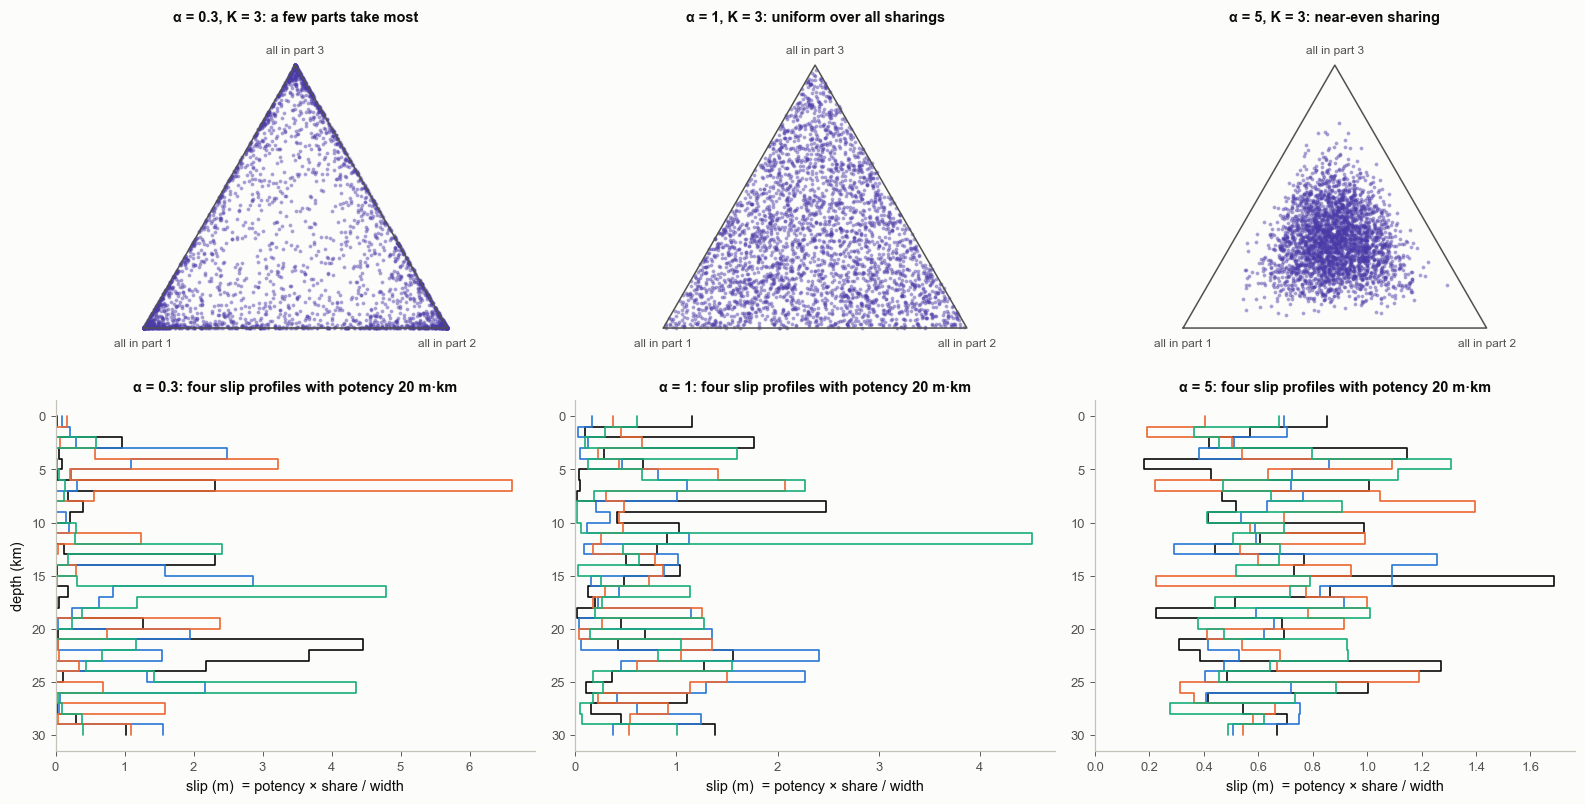

In [9]:
fig, axs = plt.subplots(2, 3, figsize=(14.5, 7.4), gridspec_kw=dict(height_ratios=[1, 1.05]))
for j, a_ in enumerate(alphas):
    ax = axs[0, j]
    W3 = dirichlet_draws(a_, 3, 3000, 20 + j)
    tx, ty = tern(W3)
    ax.plot([0, 1, 0.5, 0], [0, 0, np.sqrt(3) / 2, 0], color=S.INK2, lw=1)
    ax.scatter(tx, ty, s=2.5, color=S.VIOLET, alpha=0.35)
    for (px, py, lab) in [(0, 0, "all in part 1"), (1, 0, "all in part 2"), (0.5, np.sqrt(3) / 2, "all in part 3")]:
        ax.text(px, py + (0.04 if py > 0 else -0.06), lab, ha="center", fontsize=7.8, color=S.INK2)
    ax.set_xlim(-0.12, 1.12); ax.set_ylim(-0.12, 0.98); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"α = {a_:g}, K = 3: " + {0.3: "a few parts take most", 1.0: "uniform over all sharings",
                                         5.0: "near-even sharing"}[a_], fontsize=9.5)
    ax = axs[1, j]
    Wk = dirichlet_draws(a_, Nf, 4, 30 + j)
    for i in range(4):
        step(ax, P0 * Wk[i] / wz, color=shades[i], lw=1.1)
    ax.invert_yaxis(); ax.set_xlabel("slip (m)  = potency × share / width")
    ax.set_xlim(0, None)
    if j == 0:
        ax.set_ylabel("depth (km)")
    ax.set_title(f"α = {a_:g}: four slip profiles with potency {P0:g} m·km", fontsize=9.5)
fig.tight_layout()
bk.savefig(fig, "2-11_dirichlet")
plt.show()

**How to read it.** Top: each dot is one way of sharing a total among three parts; a corner means everything in one
part. With α = 0.3 the dots crowd the corners and edges, with α = 1 they fill the triangle evenly, with α = 5 they
gather in the middle. Bottom: 30-patch slip profiles with the same total potency. Small α gives a few strong
patches, large α gives slip spread evenly over the whole fault; all are positive and all have exactly the same total
(printed sums).

**Common misreadings.**
* *"Dirichlet with α = 1 is uninformative."* It is uniform over the ways of sharing, but it still fixes the total
  and the sign. Those are strong, and here wanted, constraints.
* *"The total must then be known exactly."* No: put a prior on the total (for example log-normal around a seismic
  moment) and a Dirichlet on the shares, as section 6 does.

## 5. Prior-predictive checks: simulate before you fit

**In plain words.** A prior on 30 slip values is hard to judge by staring at it. Its consequences are easy to judge:
draw slip profiles from the prior, run them through the forward model, and look at the totals and the predicted
surface motion. If the prior makes earthquakes ten times too big, or half of them slip the wrong way, it does not say
what you know. Revise it, and check again. Doing this before fitting keeps the data from leaking into the choice.

**Precisely.** The **prior-predictive distribution** is
$p(\mathbf d) = \int p(\mathbf d\mid\mathbf s)\,p(\mathbf s)\,d\mathbf s$: the data you would expect before
observing anything. A **prior-predictive check** compares draws from it, or summaries of them, with what is
physically plausible. Here the assumed background knowledge is: the fault is right-lateral (slip $\ge 0$), and a
seismic moment puts the potency near 20 m·km (in this synthetic example, the true value). The forward model is the
30-patch antiplane fault of 2.07 with 24 stations.

**Worked example.** Four priors, each checked by 4,000 draws:
(A) "vague": independent $\mathcal N(0, 10^2)$ m per patch;
(B) independent half-normal, scale 2 m per patch (looks reasonable patch by patch);
(C) independent half-normal, with the scale revised so that the expected potency is 20 m·km;
(D) potency log-normal (median 20 m·km, log-sd 0.1) times Dirichlet(α = 1) shares.

In [10]:
xs = np.array([1, 2, 3, 4, 6, 9, 13, 18, 25, 35, 50, 70.0])
xs = np.sort(np.r_[-xs, xs])                                                # 24 stations (km)


def patch_disp(x, z1, z2):
    return (np.arctan(z2 / x) - np.arctan(z1 / x)) / np.pi


Gf = 1000.0 * np.array([[patch_disp(x, z_edges[j], z_edges[j + 1]) for j in range(Nf)] for x in xs])   # mm per m
s_true = 2.0 * np.exp(-0.5 * ((zc - 12.0) / 4.0) ** 2)                                                  # m
sig_f = 3.0
d_f = Gf @ s_true + sig_f * np.random.default_rng(42).standard_normal(xs.size)
pot = lambda S_: S_ @ wz                                                                                 # m km
print(f"true potency {pot(s_true):.2f} m km;  largest observed |displacement| {np.abs(d_f).max():.0f} mm")
hn_rev = P0 / (Nf * np.sqrt(2 / np.pi))
print(f"revised half-normal scale so that E[potency] = {P0:g} m km: {hn_rev:.3f} m per patch")
n5 = 4000
r5 = np.random.default_rng(6)
tot_D = np.exp(np.log(P0) + 0.1 * r5.standard_normal(n5))
prior5 = {
    "(A) vague N(0, 10²)": r5.normal(0, 10, (n5, Nf)),
    "(B) half-normal 2 m": np.abs(r5.normal(0, 2, (n5, Nf))),
    "(C) half-normal, revised": np.abs(r5.normal(0, hn_rev, (n5, Nf))),
    "(D) potency × Dirichlet(1)": tot_D[:, None] * dirichlet_draws(1.0, Nf, n5, 7) / wz,
}
pp = {}
print(f"\n{'prior':28s} {'potency 5-50-95 % (m km)':>28s} {'P(potency < 0)':>15s} {'max|u| 5-50-95 % (mm)':>26s} {'share of observed max|d| quantile':>34s}")
for k, S_ in prior5.items():
    U_ = S_ @ Gf.T
    mx = np.abs(U_).max(1)
    pq = np.percentile(pot(S_), [5, 50, 95])
    mq = np.percentile(mx, [5, 50, 95])
    pp[k] = dict(U=U_, pot=pot(S_), mx=mx)
    print(f"{k:28s} {pq[0]:8.1f} {pq[1]:8.1f} {pq[2]:8.1f}   {np.mean(pot(S_) < 0):13.3f}   {mq[0]:7.0f} {mq[1]:7.0f} {mq[2]:7.0f}"
          f"   {np.mean(mx < np.abs(d_f).max()):20.3f}")

true potency 20.03 m km;  largest observed |displacement| 280 mm
revised half-normal scale so that E[potency] = 20 m km: 0.836 m per patch

prior                            potency 5-50-95 % (m km)  P(potency < 0)      max|u| 5-50-95 % (mm)  share of observed max|d| quantile
(A) vague N(0, 10²)             -88.5      0.3     89.8           0.498       514    1973    5320                  0.008
(B) half-normal 2 m              37.6     47.9     59.1           0.000       509     795    1421                  0.000
(C) half-normal, revised         15.6     20.0     24.8           0.000       210     332     585                  0.288
(D) potency × Dirichlet(1)       17.0     20.1     23.7           0.000       212     322     659                  0.332


saved figures/2-11_prior_predictive.png


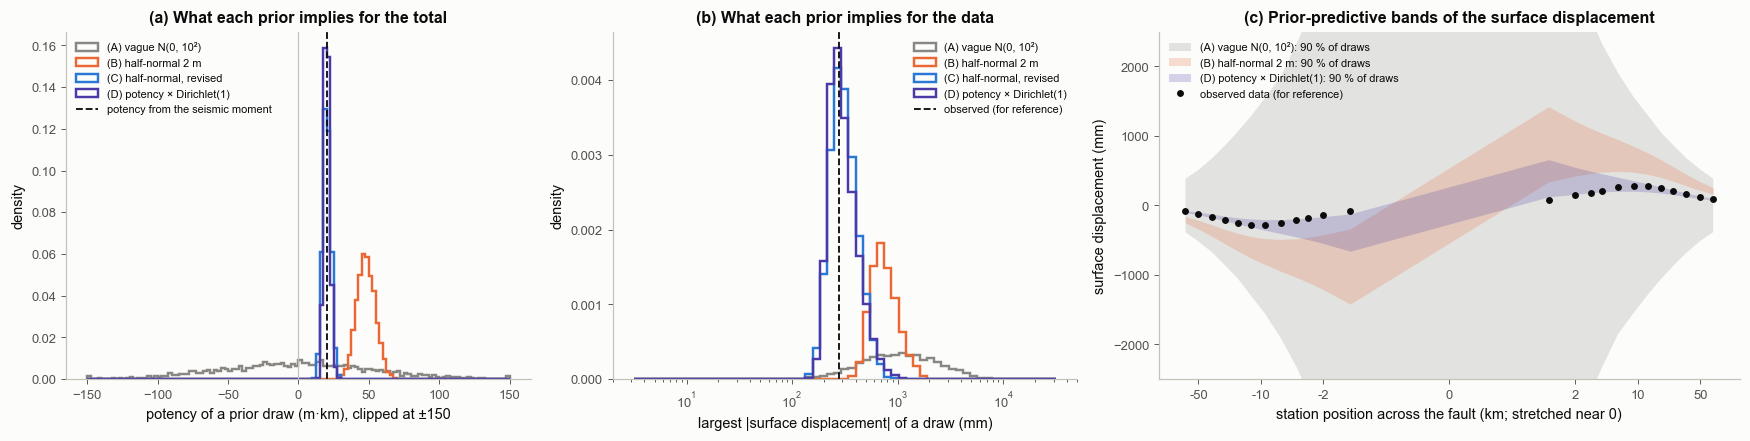

In [11]:
pcol = {k: c for k, c in zip(prior5, [S.MUTED, S.ORANGE, S.BLUE, S.VIOLET])}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.1), gridspec_kw=dict(width_ratios=[1, 1, 1.25]))
ax = axs[0]
bins_p = np.linspace(-150, 150, 121)
for k in prior5:
    ax.hist(np.clip(pp[k]["pot"], -150, 150), bins=bins_p, density=True, histtype="step", lw=1.6, color=pcol[k], label=k)
ax.axvline(P0, color=S.INK, lw=1.2, ls="--", label="potency from the seismic moment")
ax.axvline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("potency of a prior draw (m·km), clipped at ±150"); ax.set_ylabel("density")
ax.set_title("(a) What each prior implies for the total")
ax.legend(fontsize=7.2, loc="upper left")
ax = axs[1]
bins_m = np.logspace(0.5, 4.5, 60)
for k in prior5:
    ax.hist(pp[k]["mx"], bins=bins_m, density=True, histtype="step", lw=1.6, color=pcol[k], label=k)
ax.axvline(np.abs(d_f).max(), color=S.INK, lw=1.2, ls="--", label="observed (for reference)")
ax.set_xscale("log"); ax.set_xlabel("largest |surface displacement| of a draw (mm)"); ax.set_ylabel("density")
ax.set_title("(b) What each prior implies for the data")
ax.legend(fontsize=7.2, loc="upper right")
ax = axs[2]
for k in ["(A) vague N(0, 10²)", "(B) half-normal 2 m", "(D) potency × Dirichlet(1)"]:
    lo_, hi_ = np.percentile(pp[k]["U"], [5, 95], axis=0)
    ax.fill_between(xs, lo_, hi_, color=pcol[k], alpha=0.22, lw=0, label=f"{k}: 90 % of draws")
ax.plot(xs, d_f, "o", color=S.INK, ms=3.5, label="observed data (for reference)")
ax.set_xscale("symlog", linthresh=1); ax.set_ylim(-2500, 2500)
tk = [-50, -10, -2, 0, 2, 10, 50]
ax.set_xticks(tk); ax.set_xticklabels([str(t_) for t_ in tk]); ax.minorticks_off()
ax.set_xlabel("station position across the fault (km; stretched near 0)"); ax.set_ylabel("surface displacement (mm)")
ax.set_title("(c) Prior-predictive bands of the surface displacement")
ax.legend(fontsize=7.2, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-11_prior_predictive")
plt.show()

**How to read it.** (a) The vague prior (A) implies potencies spread far beyond the plausible total, half of them
negative (printed share): it says a left-lateral earthquake ten times too big is as likely as the real one. Prior (B)
looks sensible patch by patch, yet its implied total is far above 20 m·km: 30 patches of about a metre each add up.
The revised half-normal (C) centres the total, and (D) controls it directly. (b) The same story in data space: under
(A) and (B) the observed displacements would be an unusually small outcome (printed quantile of the observed maximum
within each prior-predictive distribution); under (C) and (D) they are an ordinary one. (c) The bands of predicted
surface displacement: (A) is symmetric about zero and huge, (B) is one-signed but too large, (D) brackets the data.

The check used only background knowledge (sign and potency); the observed data are drawn for reference. Choosing a
prior *because* it brackets these particular data would use the data twice.

**Common misreadings.**
* *"A wide prior is a safe prior."* (A) is wide, and it is confidently wrong about the size and sign of the event.
* *"A prior that is reasonable for each parameter is reasonable for the model."* (B) is the counterexample: what
  looks modest per patch adds up over 30 patches. Always check the implied totals and predicted data.

## 6. Same data, different priors: where the data decide and where the prior does

**In plain words.** Fit the same 24 data with several priors. Where the stations see the fault well (the shallow
part), every prior gives nearly the same slip: the data decide. Where they see it poorly (deep), each prior returns
something close to its own preference. Measuring this patch by patch tells you which parts of a result to trust.

**Precisely.** For a Gaussian prior with standard deviation $\sigma_{\rm prior}$ the **shrinkage ratio**
$\sigma_{\rm post}/\sigma_{\rm prior}$ is near 0 where the data dominate and near 1 where the prior dominates. For
non-Gaussian priors there is no closed form; we draw samples from the posterior with **NUTS**, a sampling algorithm
that 2.16-2.19 explain (2.18 is NUTS itself). For now it is a black box that returns posterior draws; the printed
checks (**R-hat** close to 1, many **effective samples**, no **divergences**) say that its four independent runs agree
and that it reported no numerical trouble (2.19 explains them). Priors compared: (A) vague, (C) revised half-normal,
(D) potency × Dirichlet, and a smooth Gaussian (sd 2 m, ℓ = 5 km). Gaussian cases are exact (closed form, 2.08).

In [12]:
Cd = sig_f ** 2 * np.eye(xs.size)


def gauss_post(Cm, m0=None):
    m0 = np.zeros(Nf) if m0 is None else m0
    Pm = np.linalg.inv(Cm)
    A_ = Gf.T @ np.linalg.solve(Cd, Gf) + Pm
    C_ = np.linalg.inv(A_)
    return C_ @ (Gf.T @ np.linalg.solve(Cd, d_f) + Pm @ m0), C_


postA = gauss_post(100.0 * np.eye(Nf))
postS = gauss_post(sq_exp_cov(5.0, 2.0))
Gj, dj = jnp.asarray(Gf), jnp.asarray(d_f)


def model_C():
    s = numpyro.sample("s", dist.HalfNormal(hn_rev).expand([Nf]))
    numpyro.sample("d", dist.Normal(Gj @ s, sig_f), obs=dj)


def model_D():
    tot = numpyro.sample("tot", dist.LogNormal(np.log(P0), 0.1))
    w = numpyro.sample("w", dist.Dirichlet(jnp.ones(Nf)))
    s = numpyro.deterministic("s", tot * w / jnp.asarray(wz))
    numpyro.sample("d", dist.Normal(Gj @ s, sig_f), obs=dj)


post_s = {}
for nm, mdl in [("(C) half-normal, revised", model_C), ("(D) potency × Dirichlet(1)", model_D)]:
    t0 = time.time()
    mc = MCMC(NUTS(mdl, target_accept_prob=0.9), num_warmup=1000, num_samples=1000, num_chains=4,
              chain_method="parallel", progress_bar=False)
    mc.run(jax.random.PRNGKey(1), extra_fields=("diverging",))
    sch = np.asarray(mc.get_samples(group_by_chain=True)["s"])
    post_s[nm] = sch.reshape(-1, Nf)
    print(f"{nm}: NUTS {time.time() - t0:.1f} s, max R-hat {max(D.rhat(sch[:, :, j]) for j in range(Nf)):.3f}, "
          f"min ESS {min(D.ess(sch[:, :, j]) for j in range(Nf)):.0f}, divergences {int(np.sum(mc.get_extra_fields()['diverging']))}")
sdA = np.sqrt(np.diag(postA[1]))
shal, deep = zc < 8, zc > 22
print(f"\n(A) vague prior: shrinkage sd_post / sd_prior, median over patches shallower than 8 km {np.median(sdA[shal] / 10):.3f}, "
      f"deeper than 22 km {np.median(sdA[deep] / 10):.3f}")
sdS = np.sqrt(np.diag(postS[1]))
print(f"smooth prior: shrinkage, shallower than 8 km {np.median(sdS[shal] / 2):.3f}, deeper than 22 km {np.median(sdS[deep] / 2):.3f}")
means = {"(A) vague N(0, 10²)": postA[0], "smooth Gaussian": postS[0],
         **{k: v.mean(0) for k, v in post_s.items()}}
mm = np.array(list(means.values()))
print("spread of the posterior means across the four priors (max - min), median over patches: "
      f"shallower than 8 km {np.median(np.ptp(mm[:, shal], axis=0)):.3f} m, deeper than 22 km {np.median(np.ptp(mm[:, deep], axis=0)):.3f} m")
for k, v in means.items():
    print(f"  {k:28s} rms error vs true slip {np.sqrt(np.mean((v - s_true) ** 2)):.3f} m;  potency of the mean {pot(v):6.2f} m km")
for k, v in post_s.items():
    print(f"  {k:28s} posterior mean: peak {v.mean(0).max():.2f} m (true {s_true.max():.2f}); median deeper than 22 km "
          f"{np.median(v.mean(0)[deep]):.2f} m (true {np.median(s_true[deep]):.3f} m)")

(C) half-normal, revised: NUTS 2.1 s, max R-hat 1.004, min ESS 1746, divergences 0


(D) potency × Dirichlet(1): NUTS 2.9 s, max R-hat 1.003, min ESS 3835, divergences 0

(A) vague prior: shrinkage sd_post / sd_prior, median over patches shallower than 8 km 0.774, deeper than 22 km 0.942
smooth prior: shrinkage, shallower than 8 km 0.035, deeper than 22 km 0.327
spread of the posterior means across the four priors (max - min), median over patches: shallower than 8 km 0.501 m, deeper than 22 km 1.234 m
  (A) vague N(0, 10²)          rms error vs true slip 1.016 m;  potency of the mean  20.27 m km
  smooth Gaussian              rms error vs true slip 0.165 m;  potency of the mean  19.89 m km
  (C) half-normal, revised     rms error vs true slip 0.313 m;  potency of the mean  20.82 m km
  (D) potency × Dirichlet(1)   rms error vs true slip 0.390 m;  potency of the mean  20.64 m km
  (C) half-normal, revised     posterior mean: peak 1.86 m (true 1.98); median deeper than 22 km 0.29 m (true 0.005 m)
  (D) potency × Dirichlet(1)   posterior mean: peak 2.52 m (true 1.98); med

saved figures/2-11_data_vs_prior.png


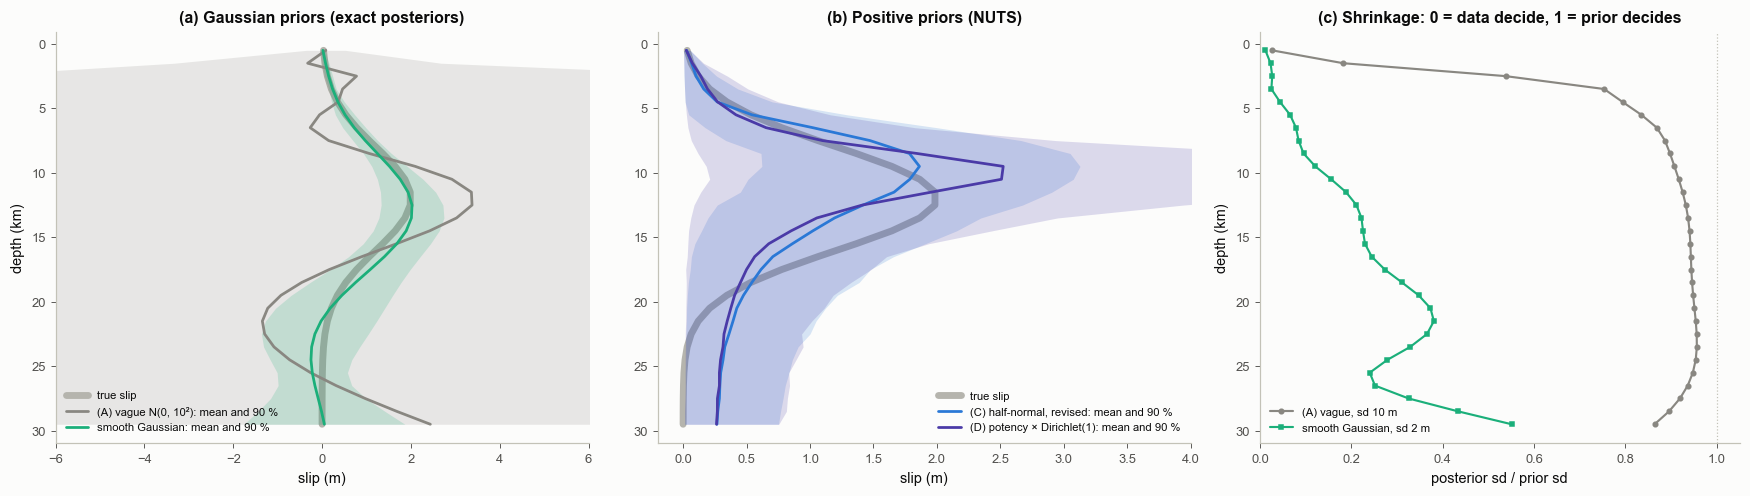

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.9]))
TRUE_KW = dict(color="#b5b4ad", lw=4.5, solid_capstyle="round", zorder=1, label="true slip")
ax = axs[0]
ax.plot(s_true, zc, **TRUE_KW)
for k, (m_, C_), c in [("(A) vague N(0, 10²)", postA, S.MUTED), ("smooth Gaussian", postS, S.AQUA)]:
    sd_ = np.sqrt(np.diag(C_))
    ax.fill_betweenx(zc, m_ - 1.645 * sd_, m_ + 1.645 * sd_, color=c, alpha=0.18, lw=0)
    ax.plot(m_, zc, color=c, lw=1.8, label=f"{k}: mean and 90 %")
ax.invert_yaxis(); ax.set_xlim(-6, 6); ax.set_xlabel("slip (m)"); ax.set_ylabel("depth (km)")
ax.set_title("(a) Gaussian priors (exact posteriors)")
ax.legend(fontsize=7.4, loc="lower left")
ax = axs[1]
ax.plot(s_true, zc, **TRUE_KW)
for k, c in [("(C) half-normal, revised", S.BLUE), ("(D) potency × Dirichlet(1)", S.VIOLET)]:
    lo_, hi_ = np.percentile(post_s[k], [5, 95], axis=0)
    ax.fill_betweenx(zc, lo_, hi_, color=c, alpha=0.18, lw=0)
    ax.plot(post_s[k].mean(0), zc, color=c, lw=1.8, label=f"{k}: mean and 90 %")
ax.invert_yaxis(); ax.set_xlim(-0.2, 4); ax.set_xlabel("slip (m)")
ax.set_title("(b) Positive priors (NUTS)")
ax.legend(fontsize=7.4, loc="lower right")
ax = axs[2]
ax.plot(sdA / 10.0, zc, "o-", color=S.MUTED, ms=3, lw=1.4, label="(A) vague, sd 10 m")
ax.plot(sdS / 2.0, zc, "s-", color=S.AQUA, ms=3, lw=1.4, label="smooth Gaussian, sd 2 m")
ax.axvline(1, color=S.AXIS, lw=0.8, ls=":")
ax.invert_yaxis(); ax.set_xlim(0, 1.05)
ax.set_xlabel("posterior sd / prior sd"); ax.set_ylabel("depth (km)")
ax.set_title("(c) Shrinkage: 0 = data decide, 1 = prior decides")
ax.legend(fontsize=7.4, loc="lower left")
fig.tight_layout()
bk.savefig(fig, "2-11_data_vs_prior")
plt.show()

**How to read it.** (a) The vague prior lets slip below a few kilometres swing over metres in both directions, with
a 90 % band wider than the plot; the smooth prior ties neighbouring patches together and follows the true slip.
(b) The two positive priors follow the true slip near the surface. Below 22 km, where the true slip is close to zero,
both return a mean of a few tenths of a metre with a wide band (printed): a positive quantity that the data cannot pin
down has a positive mean, because the prior forbids the negative half. The Dirichlet prior also puts the peak higher
than the half-normal (printed peaks). (c) The shrinkage ratio. For the vague prior it is small only in the top few
kilometres and close to 1 below: there the answer is the prior's. The smooth prior shrinks far more at every depth
(printed medians), because each patch borrows information from its neighbours; that borrowing is itself an
assumption. The printed spread of the posterior means across the four priors tells the same story in metres: smaller
near the surface than at depth.

**Common misreadings.**
* *"The posterior is what the data say."* It is what the data and the prior say together; (c) shows, patch by patch,
  how much is which.
* *"If two priors give the same answer, the answer is data-driven."* Only where the shrinkage ratio is small. Two
  priors with similar preferences can agree at depth for reasons that have nothing to do with the data.

## 7. Improper priors (optional)

**In plain words.** A "prior" that is flat over all real numbers cannot be normalised: its total probability is
infinite. Such an **improper prior** is sometimes harmless, because multiplying by the likelihood can still give a
proper posterior. That happens only if the data constrain every direction of the model. When some slip patterns are
invisible to the stations, the posterior is improper too, and no sampler can give a meaningful answer.

**Precisely.** The **precision** matrix is the inverse of a covariance (2.08): large precision, small uncertainty.
With a flat prior on $\mathbf s$, the posterior is Gaussian with precision $\mathbf G^\top\mathbf C_d^{-1}\mathbf G$.
It is proper only if this matrix has no zero eigenvalue (eigenvalue, 2.06): a zero eigenvalue is a direction with
zero precision, so infinite variance. Its eigenvalues are the squared singular values of the whitened forward
operator $\mathbf G/\sigma$ (SVD and rank, 2.06), which we compute from the SVD because forming
$\mathbf G^\top\mathbf G$ first loses half of the significant digits (2.06, section 6). For the 24-station antiplane
fault the stations come in mirror pairs, so the rank is 12 (as in 2.07): 18 directions have zero precision. Any
independent proper prior with standard deviation $\sigma_{\rm prior}$ adds $\mathbf I/\sigma_{\rm prior}^2$ and lifts
every eigenvalue to at least $1/\sigma_{\rm prior}^2$.

In [14]:
sv_w = np.linalg.svd(Gf / sig_f, compute_uv=False)
rank_f = int(np.sum(sv_w > sv_w[0] * 1e-10))                       # the same threshold as 2.07
ev_flat = np.zeros(Nf)
ev_flat[:rank_f] = sv_w[:rank_f] ** 2                               # nonzero eigenvalues; the rest are exactly zero
ev_A = ev_flat + 1.0 / 100.0
print(f"whitened G: {sv_w.size} singular values, rank {rank_f}; posterior precision with a flat prior has {rank_f} nonzero "
      f"eigenvalues (smallest {ev_flat[rank_f - 1]:.2e} per m^2) and {Nf - rank_f} zero ones")
print(f"singular values beyond the rank: largest {sv_w[rank_f:].max():.1e} (round-off)")
print(f"with the vague N(0, 10^2) prior the smallest eigenvalue is {ev_A.min():.4f} = 1/10^2: every direction proper")

whitened G: 24 singular values, rank 12; posterior precision with a flat prior has 12 nonzero eigenvalues (smallest 1.25e-09 per m^2) and 18 zero ones
singular values beyond the rank: largest 6.3e-15 (round-off)
with the vague N(0, 10^2) prior the smallest eigenvalue is 0.0100 = 1/10^2: every direction proper


saved figures/2-11_improper.png


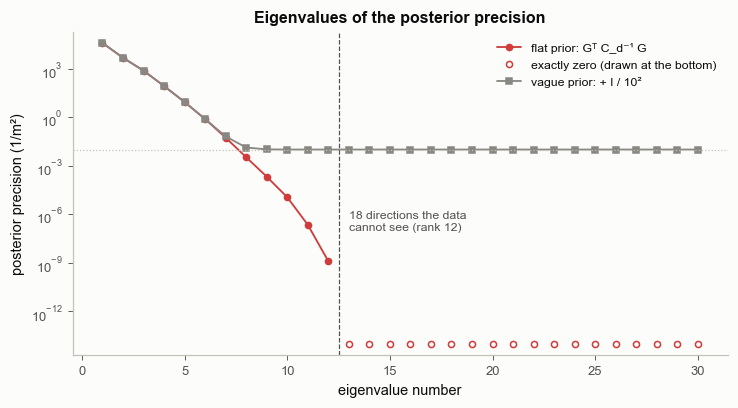

In [15]:
fig, ax = plt.subplots(figsize=(6.8, 3.8))
floor = 1e-14
ax.semilogy(np.arange(1, rank_f + 1), ev_flat[:rank_f], "o-", color=S.BAD, ms=4, lw=1.2, label="flat prior: Gᵀ C_d⁻¹ G")
ax.semilogy(np.arange(rank_f + 1, Nf + 1), np.full(Nf - rank_f, floor), "o", color=S.BAD, ms=4, mfc="none",
            label="exactly zero (drawn at the bottom)")
ax.semilogy(np.arange(1, Nf + 1), ev_A, "s-", color=S.MUTED, ms=4, lw=1.2, label="vague prior: + I / 10²")
ax.axhline(1 / 100.0, color=S.AXIS, lw=0.8, ls=":")
ax.axvline(rank_f + 0.5, color=S.INK2, lw=0.8, ls="--")
ax.text(rank_f + 1, 1e-7, f"{Nf - rank_f} directions the data\ncannot see (rank {rank_f})", fontsize=8, color=S.INK2)
ax.set_ylim(floor / 5, ev_flat.max() * 5)
ax.set_xlabel("eigenvalue number"); ax.set_ylabel("posterior precision (1/m²)")
ax.set_title("Eigenvalues of the posterior precision")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
bk.savefig(fig, "2-11_improper")
plt.show()

**How to read it.** With a flat prior (red) the eigenvalues fall steeply and are exactly zero after the rank: in
those directions the posterior has no curvature and no finite variance; the last nonzero ones are so small (printed)
that those directions are almost as unconstrained. A proper prior (grey) puts a floor under every
eigenvalue, so every direction has a finite variance; in the invisible directions that variance is simply the prior's.

**Common misreadings.**
* *"A sampler will tell me if the posterior is improper."* Often it just wanders without converging, or a bounded
  box quietly makes it proper; the eigenvalue check is direct.

## Summary: what you know → which prior

| what you know | prior | section |
|---|---|---|
| a typical value and a typical deviation | Gaussian (normal) | 1 |
| most values small, a few large | Laplace or Student-t | 1, 2 |
| only hard bounds | uniform on the bounds, in the parameterisation you mean | 3 |
| the sign and a scale | half-normal; truncated normal if there is a preferred value | 1, 5 |
| an order of magnitude | log-normal or log-uniform | 3 |
| a total, shared among parts | (prior on the total) × Dirichlet on the shares | 4, 5 |
| smoothness / correlation between neighbours | correlated Gaussian, GP (2.12), smoothing (2.09) | 2, 6 |

Whatever the choice: simulate from it before fitting (section 5), and after fitting check where the answer is
data-driven (section 6).

**The image to keep.** A prior is a set of possible faults before the data. Draw some, push them through the forward
model, and ask whether they look like earthquakes you could believe in.

Next: [**2.12 · Gaussian processes: priors on whole functions**](2-12_gaussian_processes.ipynb).

In [16]:
print(f"notebook run time: {time.time() - T0:.0f} s")

notebook run time: 7 s
